In [9]:
# to run analysis on all columns (cells) of a csv, for active cells only 

import numpy as np 
import pandas as pd 
from pathlib import Path 
from numpy.lib.stride_tricks import sliding_window_view
import matplotlib.pyplot as plt 
from sympy import symbols, Eq, solve
from scipy.integrate import simpson
from scipy.ndimage import generic_filter
from scipy import stats
from scipy.signal import find_peaks, peak_widths

movie_path = '/Volumes/Data/2026_01_12_Gad-Gcamp_E14.5/active soma/2026_01_12_Series2_activesomas.csv'

with open(movie_path, 'r') as csv:
     first_line = csv.readline()
     your_data = csv.readlines()

ncol = first_line.count(',') + 1 #count how many ROIs were selected 
print(f"There are {ncol} ROIs in this movie")

other_signals = np.genfromtxt(movie_path, encoding='utf-8-sig', delimiter = ',', usecols=np.arange(0,ncol), dtype='f8') #adjust for the number of columns there are, should build code for this  

#speed_of_imaging = float(input("Enter the speed of imaging (seconds/image): ")) #upload the version of the code with this so people don't forget 
#speed_of_imaging = 0.522
speed_of_imaging = 0.068
dt = speed_of_imaging
print(f"Speed of imaging is {dt} seconds/image") 

activity_results=[]
num_of_events =[]
freq_of_events = []
length_of_events = []
prominences_of_events = []

counter = 0 # acts as a counter for concatenating numpy arrays, aka filtered traces, into one numpy array to be saved later on

if ncol == 1:
    n = len(other_signals)
    time_end = n*dt
    t = np.arange(0,time_end,dt)                                             
    num_frames=len(t) 

    #FFT 
    fhat_ = np.fft.fft(other_signals,num_frames)     
    PSD_ = fhat_ * np.conj(fhat_)/num_frames    
    freq_ = (1/(dt*num_frames))*np.arange(num_frames)    
    L = np.arange(1,np.floor(num_frames/2),dtype='int') 
    #plt.plot(freq_[L], PSD_[L])

    real_amplitude = np.real(PSD_)
    sqrt_real_amplitude = np.sqrt(real_amplitude)
    mean_amplitude = np.mean(sqrt_real_amplitude)
    #print(mean_amplitude)

    indices = PSD_ > mean_amplitude*10
    PSD_c = PSD_ * indices
    fhat_filt_ = indices * fhat_ 
    ffilt_ = np.fft.ifft(fhat_filt_)
    complex_ifft_output_ = np.array(ffilt_)
    ffilt_array_ = np.real(complex_ifft_output_)
    #plt.plot(t, ffilt_array_)

    # Rolling average
    y = symbols('y')
    x = dt 
    eq = Eq(4/x, y) #window size is based on time constant of 4s
    window_size = solve(eq, y)
    window = window_size[0]
    window_size = round(window)
    window_size = int(window_size)

    windows = sliding_window_view(ffilt_array_, window_shape=window_size)   #can use np.convolve with mode='same' if you want the output to have the same length as the input (by calculating the edges with partial windows)
    rolling_mean = windows.mean(axis=1)

    endpoint = time_end-(window_size-1.00000)*dt
    time = np.arange(0, endpoint, dt) #the last window-1 frames are cut off so we have to adjust the time accordingly

    # ∆F/F
    window_F0 = 85*1/dt # Moving window size (85 s for dt, in frames/s), quarter of the recording length 
    window_F0 = round(window_F0)
    percentile_value = 40 # 40th percentile, 50% would be median (which would be used for neurons with low firing rate); 40% just seems to be good and a bit more on the conservative side 
 
    F0 = generic_filter(rolling_mean, function=lambda x: np.percentile(x, percentile_value), size=window_F0)
    dF_over_F = (rolling_mean - F0) / F0*100 # turned into percentage

    dF = np.copy(dF_over_F) # make a copy 
  
    # threshold for true events via z-score
    thresholded = dF_over_F
    for i in range(len(thresholded)):
        value = thresholded[i]

        z_score = stats.zscore(dF_over_F)

        if z_score[i] < 2.17: # 97% confidence interval
            thresholded[i] = value * 0  

    # measure activity 
    auc = simpson(thresholded, time) 
    activity = auc/time_end
    print(f"Total activity is {activity} %dF/F")
    activity = activity.tolist() # need to convert numpy array to list so that we save values as floats instead of tuples 


    # measure other characteristics 
    time_threshold = 1.5/dt # threshold activity by time via minimum length of transient, 1.5 seconds
    time_apart = 0.75/dt #threshold activity by how far apart the transients are, 0.75 seconds (about 11 frames for resonant scanning)
    peaks, _ = find_peaks(dF_over_F, distance = time_apart, prominence = 2, width = time_threshold) # distance is the minimum frames between consecutive transients, prominence is how much %∆F/F higher the peak has to be to considered the peak of a true calcium transient, width is the min length of peak which is set at 1.5 seconds
    num_of_peaks = len(peaks)
    print(f"This signal has {num_of_peaks} peaks at points {peaks}")

    peak_w = peak_widths(dF_over_F, peaks, rel_height=1) #rel_height=1 means it takes the width at the base of the peak 
    widths_seconds = peak_w[0] * dt
    print(f"These events are {widths_seconds} seconds long")
    widths_seconds = widths_seconds.tolist() # need to convert numpy array to list so that we save values as floats instead of tuples 

    freq_events = num_of_peaks/time_end
    print(f"The frequency of events in this ROI is {freq_events}/s") 
   
    # find the peak prominences (basically how much ∆F/F the signal changes compared to noise)
    from scipy.signal import peak_prominences
    prominences, left_bases, right_bases = peak_prominences(dF, peaks) # left and right bases don't matter 
    prominences = prominences.tolist()

    # store number of events, frequency of events, length of events, and prominences of each event in a list 
    import pandas as pd 

    activity_results.append(activity) #append results into a list
    num_of_events.append(num_of_peaks)
    freq_of_events.append(freq_events)
    length_of_events.append(widths_seconds)
    prominences_of_events.append(prominences)

    ## no need to save a trace of only one active neuron in a recording because no correlations will be done 

    
    
else:
    for row in other_signals.T: #.T at the end turns columns into rows so that the analysis can analyze them as 'columns'
        n = len(row)
        time_end = n*dt
        t = np.arange(0,time_end,dt)                                             
        num_frames=len(t) 

        #FFT 
        fhat_ = np.fft.fft(row,num_frames)     
        PSD_ = fhat_ * np.conj(fhat_)/num_frames    
        freq_ = (1/(dt*num_frames))*np.arange(num_frames)    
        L = np.arange(1,np.floor(num_frames/2),dtype='int') 

        real_amplitude = np.real(PSD_)
        sqrt_real_amplitude = np.sqrt(real_amplitude)
        mean_amplitude = np.mean(sqrt_real_amplitude)

        indices = PSD_ > mean_amplitude*10
        PSD_c = PSD_ * indices
        fhat_filt_ = indices * fhat_ 
        ffilt_ = np.fft.ifft(fhat_filt_)
        complex_ifft_output_ = np.array(ffilt_)
        ffilt_array_ = np.real(complex_ifft_output_)
        
        # Rolling average
        y = symbols('y')
        x = dt 
        eq = Eq(4/x, y) #window size is based on time constant of 4s
        window_size = solve(eq, y)
        window = window_size[0]
        window_size = round(window)
        window_size = int(window_size)

        windows = sliding_window_view(ffilt_array_, window_shape=window_size)   #can use np.convolve with mode='same' if you want the output to have the same length as the input (by calculating the edges with partial windows)
        rolling_mean = windows.mean(axis=1)

        endpoint = time_end-(window_size-1.00000)*dt
        time = np.arange(0, endpoint, dt) #the last window-1 frames are cut off so we have to adjust the time accordingly

        # ∆F/F
        window_F0 = 85*1/dt # Moving window size (85 s for dt, in frames/s), quarter of the recording length 
        window_F0 = round(window_F0)
        percentile_value = 40 # 40th percentile, 50% would be median (which would be used for neurons with low firing rate); 40% just seems to be good and a bit more on the conservative side 
    
        F0 = generic_filter(rolling_mean, function=lambda x: np.percentile(x, percentile_value), size=window_F0)
        dF_over_F = (rolling_mean - F0) / F0*100 # turned into percentage

        dF = np.copy(dF_over_F) # make a copy 
    
        # threshold for true events via z-score
        thresholded = dF_over_F
        for i in range(len(thresholded)):
            value = thresholded[i]

            z_score = stats.zscore(dF_over_F)

            if z_score[i] < 2.17: # 97% confidence interval
                thresholded[i] = value * 0  

        if counter == 0:
            trace = thresholded # hold the first trace in a different variable to concatenate them later 
            counter += 1
        elif counter == 1:
            filt_traces = np.column_stack((trace,thresholded))
            counter += 1
        else: 
            filt_traces = np.column_stack((filt_traces,thresholded))
            counter += 1

        # measure activity 
        auc = simpson(thresholded, time) 
        activity = auc/time_end
        print(f"Total activity is {activity} %dF/F")
        activity = activity.tolist()


        # measure other characteristics 
        time_threshold = 1.5/dt # threshold activity by time via minimum length of transient, 1.5 seconds
        time_apart = 0.75/dt #threshold activity by how far apart the transients are, 0.75 seconds (about 11 frames for resonant scanning)
        peaks, _ = find_peaks(dF_over_F, distance = time_apart, prominence = 1.5, width = time_threshold) # distance is the minimum frames between consecutive transients, prominence is how much %∆F/F higher the peak has to be to considered the peak of a true calcium transient, width is the min length of peak which is set at 1.5 seconds
        num_of_peaks = len(peaks)
        print(f"This signal has {num_of_peaks} peaks at points {peaks}")

        peak_w = peak_widths(dF_over_F, peaks, rel_height=1) #rel_height=1 means it takes the width at the base of the peak 
        widths_seconds = peak_w[0] * dt
        print(f"These events are {widths_seconds} seconds long")
        widths_seconds = widths_seconds.tolist()

        freq_events = num_of_peaks/time_end
        print(f"The frequency of events in this ROI is {freq_events}/s") 
    
        # find the peak prominences (basically how much ∆F/F the signal changes compared to noise)
        from scipy.signal import peak_prominences
        prominences, left_bases, right_bases = peak_prominences(dF, peaks) # left and right bases don't matter 
        prominences = prominences.tolist()


        # store number of events, frequency of events, length of events, and prominences of each event in a list 
        import pandas as pd 

        activity_results.append(activity) #append results into a list
        num_of_events.append(num_of_peaks)
        freq_of_events.append(freq_events)
        length_of_events.append(widths_seconds)
        prominences_of_events.append(prominences)


# store these lists in a dataframe 
file_path = Path(movie_path)
filename = file_path.name
filename = filename.removesuffix(".csv")
filename_activity = filename + "_activity_results"
print(f"CSV file will be called {filename_activity}")
data = pd.DataFrame(activity_results)
data.to_csv(filename_activity+'.csv', index=False)

filename_extra = filename + "_extra_results"
print(f"CSV file will be called {filename_extra}")
extra_data = pd.DataFrame({'num_of_events':num_of_events,'freq_of_events (events/s)':freq_of_events, 'length_of_events (s)':length_of_events, 'prominences_of_events (% ∆F/F)':prominences_of_events})
extra_data.to_csv(filename_extra+'.csv', index=True)

# save filtered traces in one .csv 
filename_filt_traces = filename + "_filt_traces"
print(f"CSV file will be called {filename_filt_traces}")
np.savetxt(filename_filt_traces+".csv", filt_traces, delimiter=",")


There are 3 ROIs in this movie
Speed of imaging is 0.068 seconds/image
Total activity is 3.7715523927392836 %dF/F
This signal has 2 peaks at points [ 183 3826]
These events are [ 5.78  10.064] seconds long
The frequency of events in this ROI is 0.007352941176470588/s
Total activity is 0.6260102662090131 %dF/F
This signal has 1 peaks at points [151]
These events are [9.112] seconds long
The frequency of events in this ROI is 0.003676470588235294/s
Total activity is 1.3475862784225456 %dF/F
This signal has 3 peaks at points [ 134 3272 3483]
These events are [6.052 4.692 7.14 ] seconds long
The frequency of events in this ROI is 0.011029411764705883/s
CSV file will be called 2026_01_12_Series2_activesomas_activity_results
CSV file will be called 2026_01_12_Series2_activesomas_extra_results
CSV file will be called 2026_01_12_Series2_activesomas_filt_traces


In [ ]:
# if important 
'''
    #to check if signal is lower than background, maybe use 
    if mean_amplitude < b1_mean_amplitude:  
        print("mean amplitude of calcium trace is lower than background")   
    elif mean_amplitude < b2_mean_amplitude:
        print("mean amplitude of calcium trace is lower than background")
    elif mean_amplitude < b3_mean_amplitude: 
        print("mean amplitude of calcium trace is lower than background")
    else: 
        print("mean amplitude of calcium trace is greater than background")  
''' 

In [ ]:
# to run analysis on all columns (cells) of a csv

import numpy as np 
import pandas as pd 
from pathlib import Path 
from numpy.lib.stride_tricks import sliding_window_view
import matplotlib.pyplot as plt 
from sympy import symbols, Eq, solve
from scipy.integrate import simpson
from scipy.ndimage import generic_filter
from scipy import stats
from scipy.signal import find_peaks, peak_widths

movie_path = '/Volumes/Data/2026_01_12_Gad-Gcamp_E14.5/Series 9/2026_01_12_Series9_neurites.csv'

with open(movie_path, 'r') as csv:
     first_line = csv.readline()
     your_data = csv.readlines()

ncol = first_line.count(',') + 1 #count how many ROIs were selected 
print(f"There are {ncol} ROIs in this movie")

other_signals = np.genfromtxt(movie_path, encoding='utf-8-sig', delimiter = ',', usecols=np.arange(0,ncol), dtype='f8') #adjust for the number of columns there are, should build code for this  

#speed_of_imaging = float(input("Enter the speed of imaging (seconds/image): ")) #upload the version of the code with this so people don't forget 
speed_of_imaging = 0.068
dt = speed_of_imaging
print(f"Speed of imaging is {dt} seconds/image") 

activity_results=[]
num_of_events =[]
freq_of_events = []
length_of_events = []
prominences_of_events = []

for row in other_signals.T: #.T at the end turns columns into rows so that the analysis can analyze them as 'columns'
    n = len(row)
    time_end = n*dt
    t = np.arange(0,time_end,dt)                                             
    num_frames=len(t) 

    #FFT 
    fhat_ = np.fft.fft(row,num_frames)     
    PSD_ = fhat_ * np.conj(fhat_)/num_frames    
    freq_ = (1/(dt*num_frames))*np.arange(num_frames)    
    L = np.arange(1,np.floor(num_frames/2),dtype='int') 

    real_amplitude = np.real(PSD_)
    sqrt_real_amplitude = np.sqrt(real_amplitude)
    mean_amplitude = np.mean(sqrt_real_amplitude)

    indices = PSD_ > mean_amplitude*5   
    PSD_c = PSD_ * indices
    fhat_filt_ = indices * fhat_ 
    ffilt_ = np.fft.ifft(fhat_filt_)
    complex_ifft_output_ = np.array(ffilt_)
    ffilt_array_ = np.real(complex_ifft_output_)

    # Rolling average
    y = symbols('y')
    x = dt 
    eq = Eq(4/x, y) #window size is based on time constant of 4s
    window_size = solve(eq, y)
    window = window_size[0]
    window_size = round(window)
    window_size = int(window_size)

    windows = sliding_window_view(ffilt_array_, window_shape=window_size)   #can use np.convolve with mode='same' if you want the output to have the same length as the input (by calculating the edges with partial windows)
    rolling_mean = windows.mean(axis=1)

    endpoint = time_end-(window_size-1.00000)*dt
    time = np.arange(0, endpoint, dt) #the last window-1 frames are cut off so we have to adjust the time accordingly

    # ∆F/F
    window_F0 = 85*1/dt # Moving window size (85 s for dt, in frames/s), quarter of the recording length 
    window_F0 = round(window_F0)
    percentile_value = 40 # 40th percentile, can be changed 
 
    F0 = generic_filter(rolling_mean, function=lambda x: np.percentile(x, percentile_value), size=window_F0)
    dF_over_F = (rolling_mean - F0) / F0*100 # turned into percentage
  
    # threshold for true events via z-score
    thresholded = dF_over_F
    for i in range(len(thresholded)):
        value = thresholded[i]

        z_score = stats.zscore(dF_over_F)

        if z_score[i] < 2.17: # 97% confidence interval
            thresholded[i] = value * 0  

    # measure other characteristics 
    time_threshold = 1.5/dt
    time_apart = 0.75/dt
    peaks, _ = find_peaks(dF_over_F, distance = time_apart, prominence = 3, width = time_threshold) # distance is the minimum frames between consecutive transients, prominence is how much %∆F/F higher the peak has to be to considered the peak of a true calcium transient, width is how long in frames the signal has to at least be (I converted this to seconds)
    num_of_peaks = len(peaks)
    print(f"This signal has {num_of_peaks} peaks at points {peaks}")

    peak_w = peak_widths(dF_over_F, peaks, rel_height=1) #rel_height=1 means it takes the width at the base of the peak 
    widths_seconds = peak_w[0] * dt
    widths_seconds = widths_seconds.tolist()
    print(f"These events are {widths_seconds} seconds long")

    freq_events = num_of_peaks/time_end
    print(f"The frequency of events in this ROI is {freq_events}/s") 
   
    # find the peak prominences (basically how much ∆F/F the signal changes compared to noise)
    from scipy.signal import peak_prominences
    prominences, left_bases, right_bases = peak_prominences(dF_over_F, peaks) # left and right bases don't matter 
    prominences = prominences.tolist()

    # secondary threshold 
    if num_of_peaks == 0:
        for i in range(len(thresholded)):
            thresholded[i] = 0

    # measure activity 
    auc = simpson(thresholded, time) 
    activity = auc/time_end
    activity = activity.tolist()
    print(f"Total activity is {activity} %dF/F")

    # store number of events, frequency of events, length of events, and prominences of each event in a list 

    activity_results.append(activity) #append results into a list
    num_of_events.append(num_of_peaks)
    freq_of_events.append(freq_events)
    length_of_events.append(widths_seconds)
    prominences_of_events.append(prominences)

# store these lists in a dataframe 
file_path = Path(movie_path)
filename = file_path.name
filename = filename.removesuffix(".csv")
filename_activity = filename + "_activity_results"
print(f"CSV file will be called {filename_activity}")
data = pd.DataFrame(activity_results)
data.to_csv(filename_activity+'.csv', index=False)

filename_extra = filename + "_extra_results"
print(f"CSV file will be called {filename_extra}")
extra_data = pd.DataFrame({'num_of_events':num_of_events,'freq_of_events (events/s)':freq_of_events, 'length_of_events (s)':length_of_events, 'prominences_of_events (% ∆F/F)':prominences_of_events})
extra_data.to_csv(filename_extra+'.csv', index=True)



There are 44 ROIs in this movie
Speed of imaging is 0.068 seconds/image
This signal has 0 peaks at points []
These events are [] seconds long
The frequency of events in this ROI is 0.0/s
Total activity is 0.0 %dF/F
This signal has 0 peaks at points []
These events are [] seconds long
The frequency of events in this ROI is 0.0/s
Total activity is 0.0 %dF/F
This signal has 0 peaks at points []
These events are [] seconds long
The frequency of events in this ROI is 0.0/s
Total activity is 0.0 %dF/F
This signal has 0 peaks at points []
These events are [] seconds long
The frequency of events in this ROI is 0.0/s
Total activity is 0.0 %dF/F
This signal has 0 peaks at points []
These events are [] seconds long
The frequency of events in this ROI is 0.0/s
Total activity is 0.0 %dF/F
This signal has 0 peaks at points []
These events are [] seconds long
The frequency of events in this ROI is 0.0/s
Total activity is 0.0 %dF/F
This signal has 0 peaks at points []
These events are [] seconds long


to visualize multiple traces at once

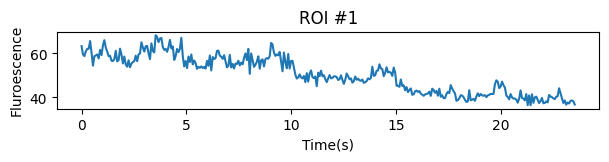

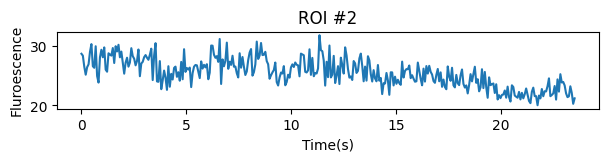

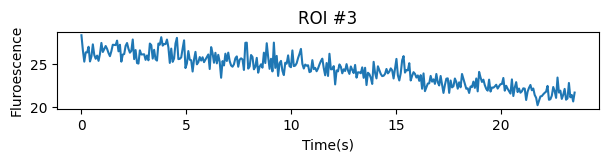

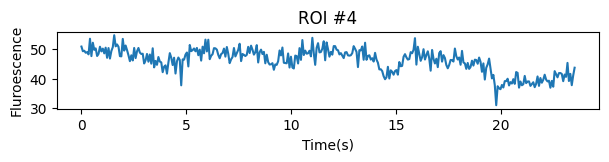

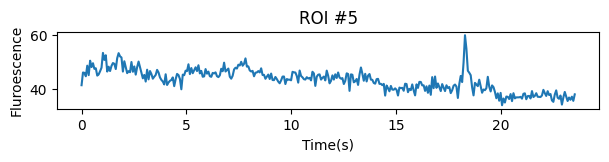

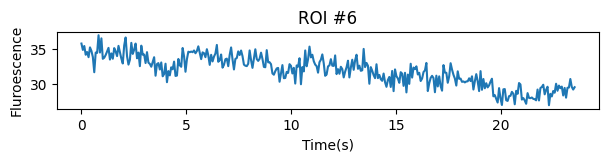

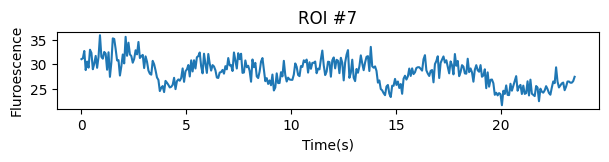

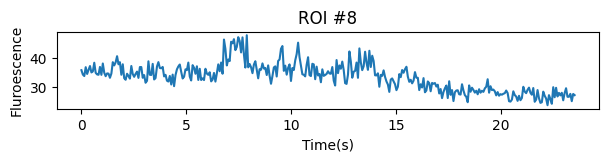

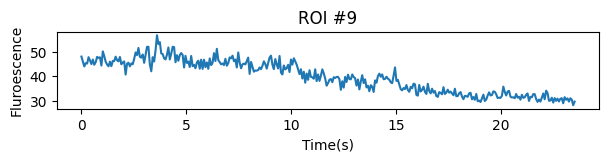

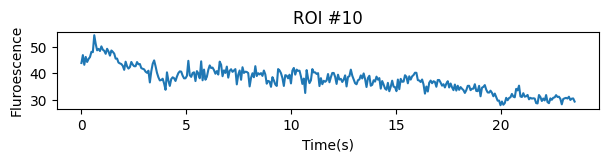

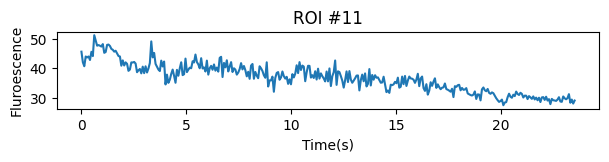

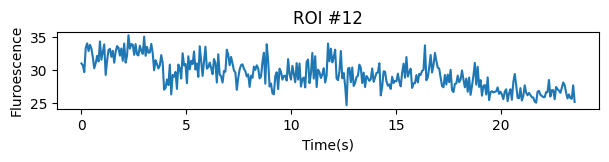

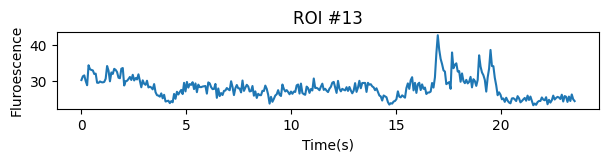

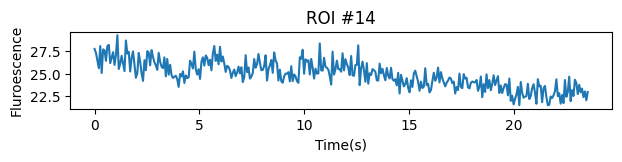

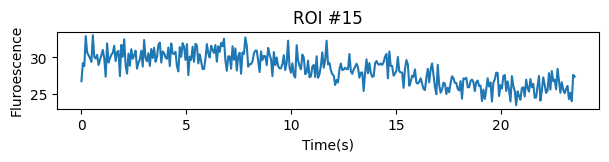

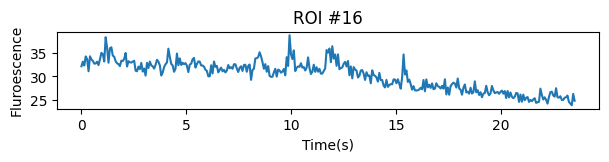

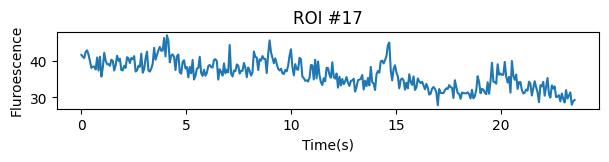

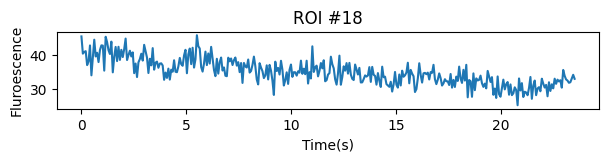

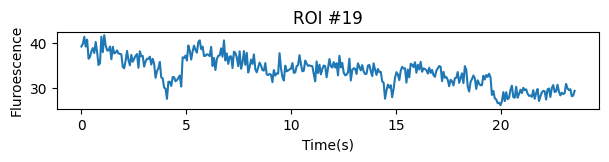

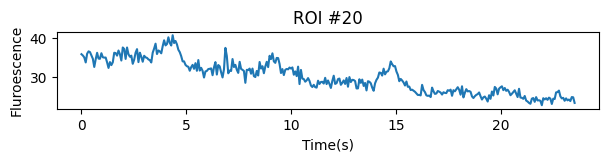

In [446]:
# to look at the trace for each ROI 
import numpy as np 
import matplotlib.pyplot as plt

num_of_rois = 20
other_signals = np.genfromtxt('/Users/Jeremy/Desktop/ROIs + measurements/2025_02_19/Series 8/2025_02_19_Series8_soma.csv', encoding='utf-8-sig', delimiter = ',', usecols=np.arange(0,num_of_rois), dtype='f8')   
dt = 0.068
                                 
i = 0
# Loop through the data to generate separate figures
while i < num_of_rois: #only using a while loop to name each ROI separately
    for data in other_signals.T: #for loop to call and plot each ROI separately 
        i += 1
        n = len(data)
        time_end = n*dt
        t = np.arange(0,time_end,dt)  
        # Create a new figure and axes in each iteration
        fig, ax = plt.subplots(figsize=(7,1))
    
        ax.plot(t, data)
        ax.set_title(f'ROI #{i}')
        ax.set_xlabel('Time(s)')
        ax.set_ylabel('Fluroescence')




# Calling plt.show() after the loop displays all generated figures
plt.show() 

Denoising steps 

Speed of imaging is 0.522 seconds/image
There are 3942 frames
This recording is 2057.724 seconds long


Text(0, 0.5, 'Intensity')

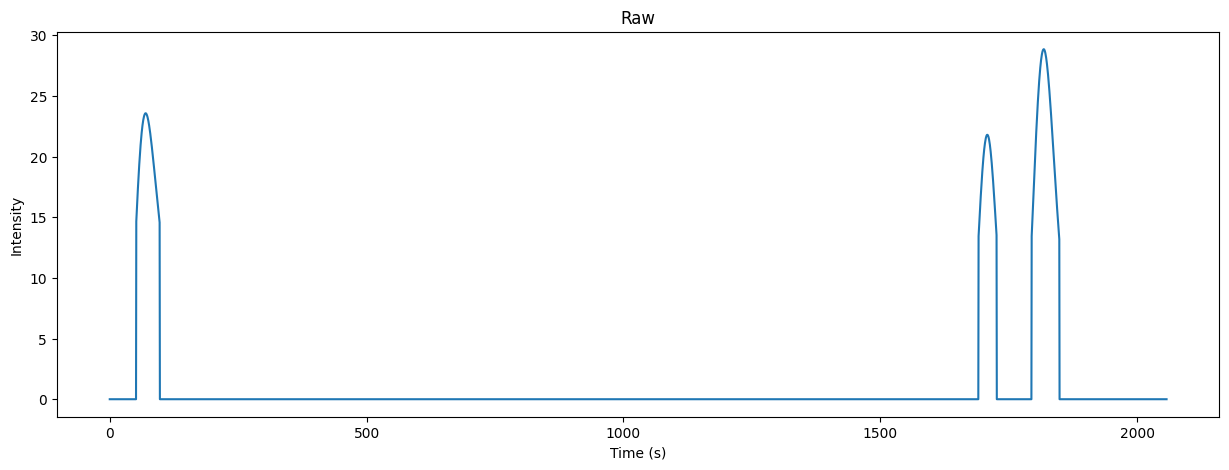

In [12]:
import numpy as np 
import matplotlib.pyplot as plt

#load data with numpy  
# use this function if you want to specify a range of columns to load: usecols(np.arange())
movie_path = '/Users/Jeremy/Desktop/Files for visual studio /2026_01_12_Series2_activesomas_filt_traces.csv'
signal = np.genfromtxt(movie_path, encoding='utf-8-sig', delimiter = ',', usecols=np.arange(2,3), dtype='f8')
 
#speed_of_imaging = float(input("Enter the speed of imaging (seconds/image): ")) #need to input because imaging speed can be different
#dt = speed_of_imaging
dt = 0.522
print(f"Speed of imaging is {dt} seconds/image") 
n = len(signal) #counting the number of images there are in the time series 
print(f"There are {n} frames")

time_end = n*dt #how long it took to take the time series (in seconds)
print(f"This recording is {time_end} seconds long")
t = np.arange(0,time_end,dt) #creates a range that allows floats (for precision), where 0 is the start, time_end is the stop (which isn't included in the range), and dt is the step size 

plt.figure(figsize=(15, 5)) 
plt.plot(t,signal)
plt.title('Raw')
plt.xlabel("Time (s)")
plt.ylabel("Intensity")

/opt/homebrew/Caskroom/miniforge/base/lib/python3.12/site-packages/matplotlib/cbook.py:1719: ComplexWarning: Casting complex values to real discards the imaginary part
  return math.isfinite(val)
/opt/homebrew/Caskroom/miniforge/base/lib/python3.12/site-packages/matplotlib/cbook.py:1355: ComplexWarning: Casting complex values to real discards the imaginary part
  return np.asarray(x, float)


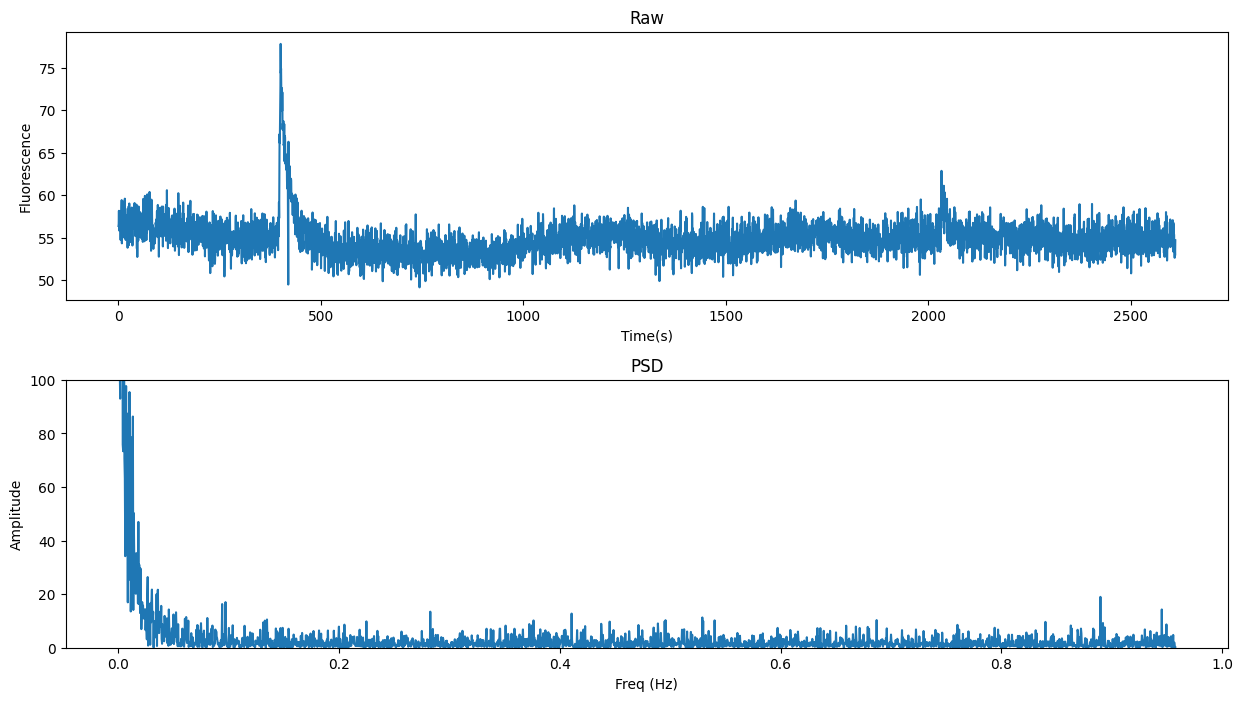

In [462]:
#FFT with numpy 

fhat = np.fft.fft(signal,n)     #compute the FFT
PSD = fhat * np.conj(fhat)/n    #Power spectrum density (gives you the magnitude of each fourier coefficient and we'll get a vector of powers at each frequency)
freq = (1/(dt*n))*np.arange(n)    #create an x-axis of frequencies 
L = np.arange(1,np.floor(n/2),dtype='int') #only plot first half (real signals are symmetric)

#plotting raw signal and power spectrum density acquired from FFT
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(15,8))
x1=t
x2=freq[L]
y1=signal
y2=PSD[L]

ax1.plot(x1, y1)
ax1.set_title("Raw")
ax1.set_xlabel('Time(s)')
ax1.set_ylabel('Fluorescence')


ax2.plot(x2, y2)
ax2.set_title("PSD")
ax2.set_xlabel("Freq (Hz)")
ax2.set_ylabel("Amplitude")
ax2.set_ylim(0,100)


plt.subplots_adjust(hspace=0.3)


In [463]:
#determine mean amplitude of PSD
power_spectrum_density = np.real(PSD) #takes only real values from the FFT
amplitude = np.sqrt(power_spectrum_density) #need to square root PSD since it is technically fhat^2

mean1s = np.mean(amplitude) #mean amplitude of power from PSD 
print(mean1s)


2.212324032166387


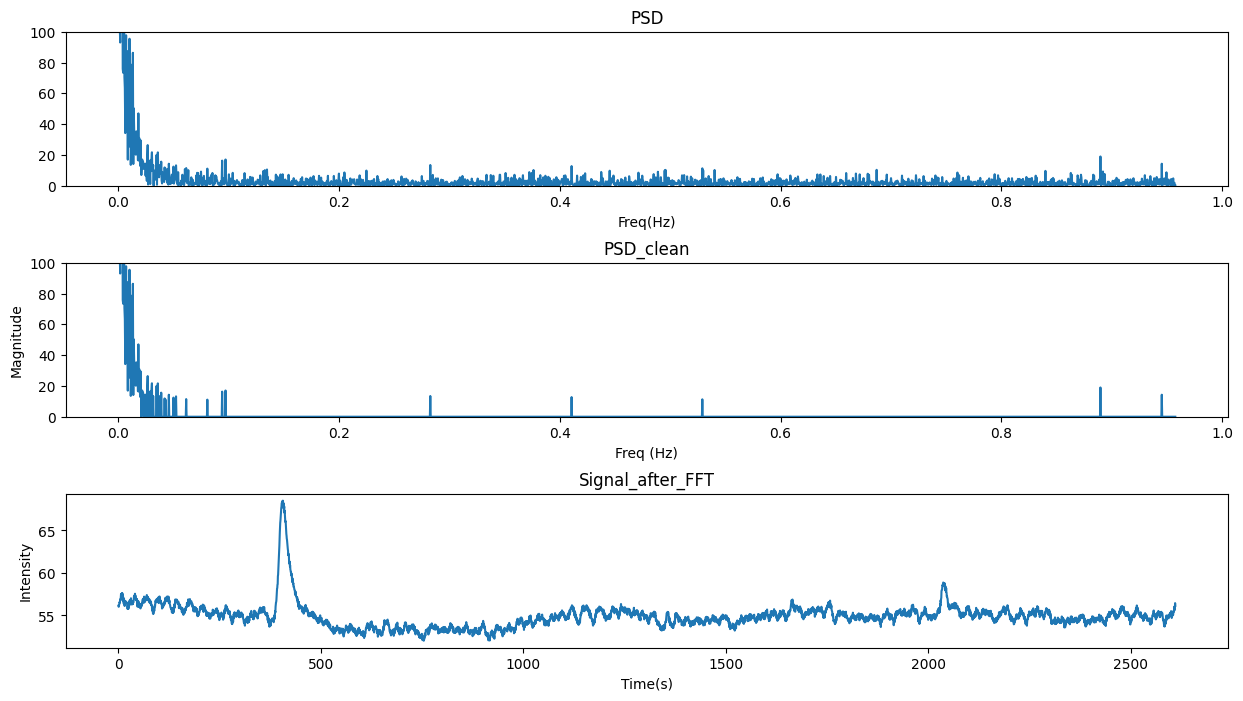

In [466]:
#Determine threshold value (can be a right above the noise floor or using a quartile approach), I chose 150% above mean 

#Set all FFT coefficients below the threshold to 0 and perform a reverse FFT to reconstruct signal without excluded frequencies

indices = PSD > mean1s * 5 #threshold PSD to 1000% times mean, the lower amplitude noise out (the noise that sticks out more)
PSD_clean = PSD * indices
fhat_filt = indices * fhat 
ffilt = np.fft.ifft(fhat_filt)
complex_ifft_output = np.array(ffilt)
float_array = np.real(complex_ifft_output)

#np.savetxt('ffilt.csv', float_array, delimiter=',') #to save filtered signal 

fig, (ax1, ax2, ax3) = plt.subplots(3, 1, figsize=(15,8))
x1=freq[L]
x2=t
y1=PSD[L]
y2=PSD_clean[L]
y3=ffilt        #can input float_array as well but output seems the same so I'm not sure what the difference is 

ax1.plot(x1, y1)
ax1.set_title("PSD")
ax1.set_xlabel('Freq(Hz)')
ax1.set_ylim(0,100)

ax2.plot(x1, y2)
ax2.set_title("PSD_clean")
ax2.set_xlabel("Freq (Hz)")
ax2.set_ylabel("Magnitude")
ax2.set_ylim(0,100)

ax3.plot(x2, y3)
ax3.set_title('Signal_after_FFT')
ax3.set_xlabel('Time(s)')
ax3.set_ylabel('Intensity')


plt.subplots_adjust(hspace=0.5)

/var/folders/l6/v6vc0z010wn87j21gw8frxb80000gn/T/ipykernel_40508/2907117075.py:4: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


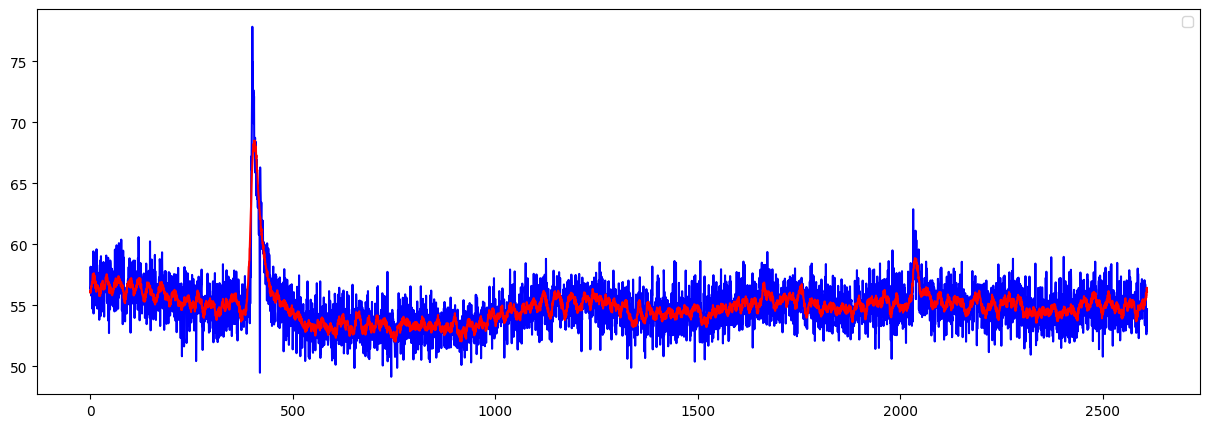

In [467]:
plt.figure(figsize=(15, 5)) 
plt.plot(t,signal,color='blue')
plt.plot(t,ffilt,color='red')
plt.legend()
plt.show()


The window size for rolling average is 8
4993 frames in the signal averaged by rolling window
Endpoint is 2606.346s
4993 time points


Text(0, 0.5, 'Fluorescence')

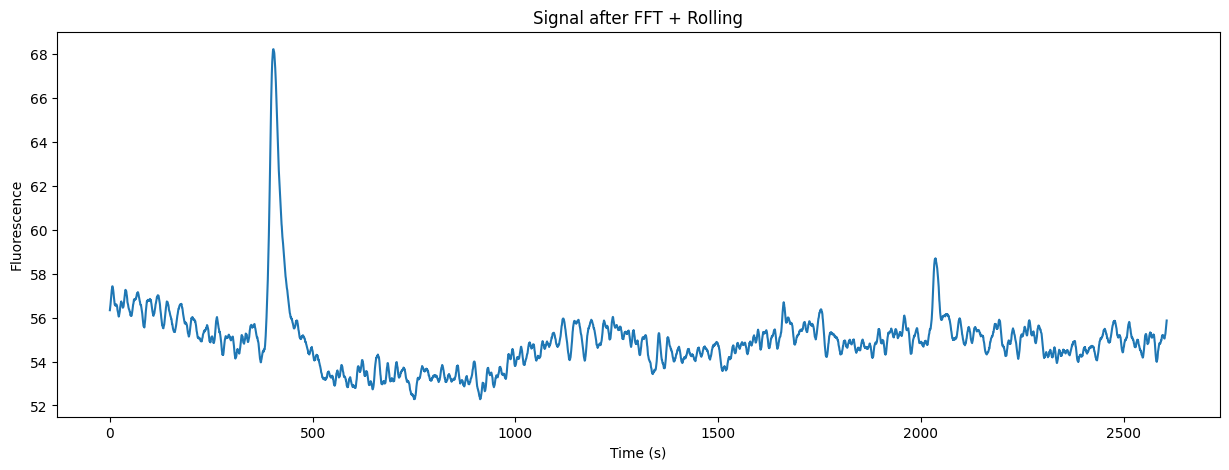

In [468]:
#Rolling average after FFT with Numpy

#make window size dependent on dt, aka images per second 
from sympy import symbols, Eq, solve 

y = symbols('y')
x = dt 
eq = Eq(4/x, y) #window size is based on time constant of 4 seconds
window_size = solve(eq, y)
window = window_size[0]
window_size = round(window) #need to round window size to nearest whole number 
window_size = int(window_size) #need to convert float to integer 
print(f"The window size for rolling average is {window_size}")
#rolling_mean = np.convolve(float_array, np.ones(window_size)/window_size, mode='valid')    #simpler rolling mean 

from numpy.lib.stride_tricks import sliding_window_view
windows = sliding_window_view(float_array, window_shape=window_size)    #can use np.convolve with mode='same' if you want the output to have the same length as the input (by calculating the edges with partial windows)
rolling_mean = windows.mean(axis=1)

print(f"{len(rolling_mean)} frames in the signal averaged by rolling window")

endpoint = time_end-(window_size-1.00000)*dt 
print(f"Endpoint is {endpoint}s") 

time = np.arange(0, endpoint, dt) #the last window-1 frames are cut off so we have to adjust the time accordingly
print(f"{len(time)} time points")

plt.figure(figsize=(15, 5)) 
plt.plot (time, rolling_mean)
plt.title('Signal after FFT + Rolling')
plt.xlabel("Time (s)")
plt.ylabel("Fluorescence")


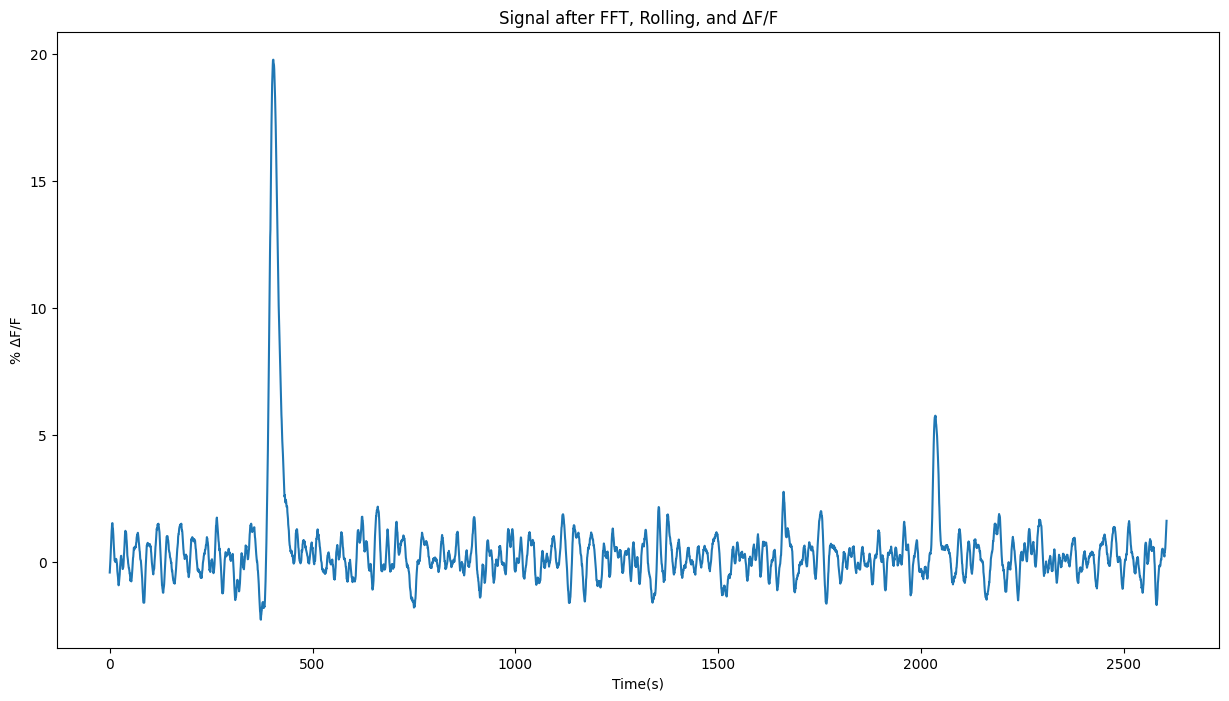

In [469]:
# first compute F0 (baseline fluorescence) using moving percentile, better for when there's slow drifts in baseline fluroscence than using a static median
    # also consider that baseline and background are different things, background is confounding noise 
# then dF/F
from scipy.ndimage import generic_filter

#parameters
window_F0 =85*1/dt # Moving window size (40s window,  dt, in frames/s)
window_F0 = round(window_F0)
percentile_value = 40 # 40th percentile

#apply moving percentage filter 
F0 = generic_filter(rolling_mean, function=lambda x: np.percentile(x, percentile_value), size=window_F0)

#noramlize data with F0 
dF_over_F = (rolling_mean - F0) / F0*100 # turned into percentage

fig, ax = plt.subplots(1,1, figsize=(15,8))                                    
x = time
y=dF_over_F
ax.plot(x,y)
ax.set_title('Signal after FFT, Rolling, and \u0394F/F')
ax.set_xlabel('Time(s)')
ax.set_ylabel('% \u0394F/F')
#plt.ylim(0,100)

dF = np.copy(dF_over_F) # need to create an independent copy of the variable to compare the arrays in the same cell for the next cell 


In [133]:
'''
#Use Numpy to create percentage-based baseline; obsolete?

F0 = np.nanmedian(rolling_mean) #can use median because there's not a lot of ongoing activity (since there's not a lot of spikes that would pull the median above true baseline), otherwise would need to identify a specific percentile 
print(F0)

dF_over_F = (rolling_mean - F0) / F0*100 #turned into percentage 

plt.plot(time, dF_over_F)
plt.xlabel("Time (s)")
plt.ylabel("% DF/F")
plt.title("Signal after FFT, Rolling, and DF/F")
plt.ylim(0, 100)
'''

'\n#Use Numpy to create percentage-based baseline; obsolete?\n\nF0 = np.nanmedian(rolling_mean) #can use median because there\'s not a lot of ongoing activity (since there\'s not a lot of spikes that would pull the median above true baseline), otherwise would need to identify a specific percentile \nprint(F0)\n\ndF_over_F = (rolling_mean - F0) / F0*100 #turned into percentage \n\nplt.plot(time, dF_over_F)\nplt.xlabel("Time (s)")\nplt.ylabel("% DF/F")\nplt.title("Signal after FFT, Rolling, and DF/F")\nplt.ylim(0, 100)\n'

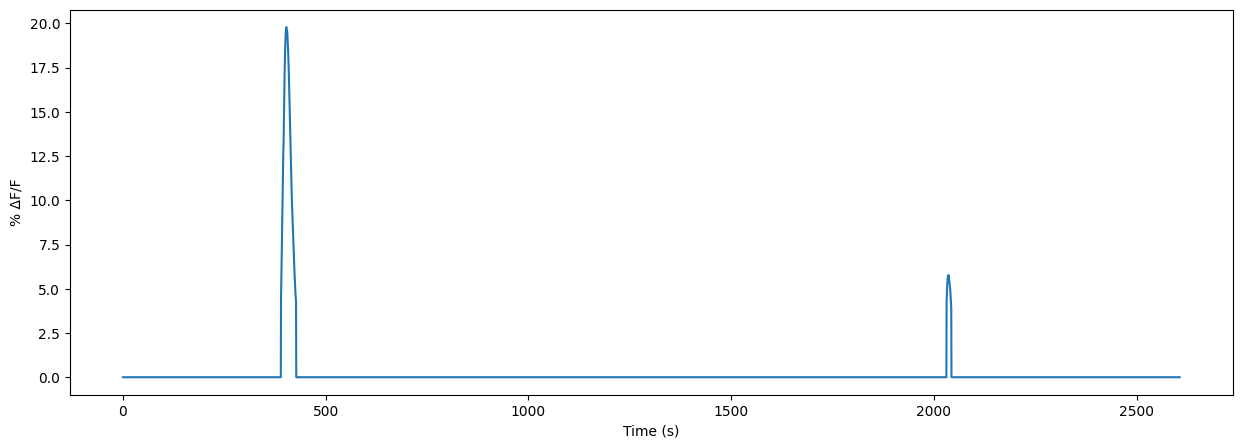

In [470]:
# event detection: applying a statistical significance threshold with z-scoring, better than setting a 10% dF/F threshold 


from scipy import stats 

thresholded = dF_over_F

for i in range(len(thresholded)):
    value = thresholded[i]

    z_score = stats.zscore(thresholded)

    if z_score[i] < 2.17: #97% confidence interval
        thresholded[i] = value * 0  #values below threshold turns to 0, cuts off the feet of signal but this is ok  


plt.figure(figsize=(15, 5)) 
plt.plot (time, thresholded)
plt.xlabel("Time (s)")
plt.ylabel("% \u0394F/F")
#plt.savefig("2026_03_05_S11_quiet_neuron2_background", format="eps")

plt.show()

# for event detection so that we can do correlations, need a rule to combine separate activity spikes that are only a few frames apart (set this to the rise time of GCaMP8m or twice the rise time); spikelet?; could also do a deconvolution of the GCaMP response (need to know rise and decay time)


In [135]:
#obsolete - event detection via setting the threshold at 10% dF/F  

'''
thresholded = dF_over_F

for i in range(len(thresholded)):
    value = thresholded[i]

    if value < 10: #threshold at 10% dF/F because noise seems to be just below it 
        thresholded[i] = value * 0  #values below threshold turns to 0, although this shortens signal so could find a better way to do this 

plt.plot(time, thresholded)
plt.title("True activity")
plt.ylabel(f"% dF/F")
plt.xlabel("Time(s)")
'''

'\nthresholded = dF_over_F\n\nfor i in range(len(thresholded)):\n    value = thresholded[i]\n\n    if value < 10: #threshold at 10% dF/F because noise seems to be just below it \n        thresholded[i] = value * 0  #values below threshold turns to 0, although this shortens signal so could find a better way to do this \n\nplt.plot(time, thresholded)\nplt.title("True activity")\nplt.ylabel(f"% dF/F")\nplt.xlabel("Time(s)")\n'

This signal has 2 peaks at points [ 773 3900]
These events are [38.106 12.528] seconds long
The frequency of events in this ROI is 0.0007662835249042146/s


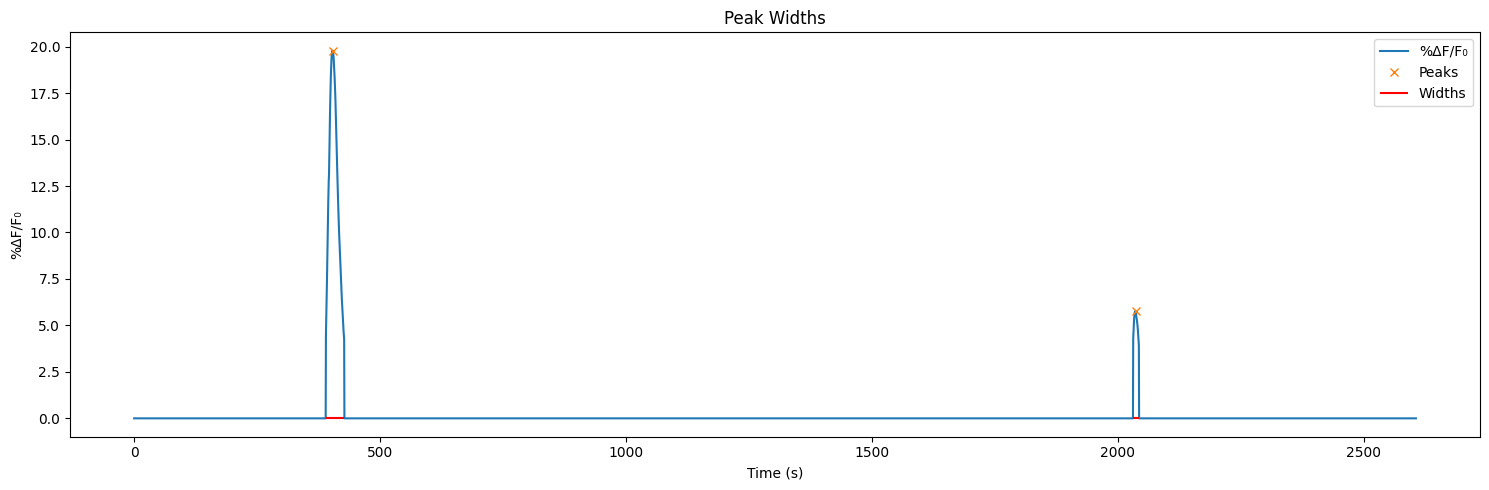

In [471]:
# event detection with peaks and lengths 

from scipy.signal import find_peaks, peak_widths


time_threshold = 1.5/dt
time_apart = 0.75/dt

peaks, _ = find_peaks(dF_over_F, distance = time_apart, prominence = 3, width = time_threshold) # distance is the minimum frames between consecutive transients, prominence is how much %∆F/F higher the peak has to be to considered the peak of a true calcium transient (for this, I use it to prevent the function from measuring multiple peaks within one transient but normally is a type of thresholding method), width is the min lenght of peak which is set at 1 second
num_of_peaks = len(peaks)
print(f"This signal has {num_of_peaks} peaks at points {peaks}")

peak_w = peak_widths(dF_over_F, peaks, rel_height=1) #rel_height=1 means it takes the width at the base of the peak 
widths_seconds = peak_w[0] * dt
print(f"These events are {widths_seconds} seconds long")

#freq_events = num_of_peaks/time_end
freq_events = num_of_peaks/time_end
print(f"The frequency of events in this ROI is {freq_events}/s") 




plt.figure(figsize=(15, 5)) 
plt.plot(time, dF_over_F, label='%ΔF/F₀')
plt.plot(time[peaks], dF_over_F[peaks], "x", label='Peaks')
plt.hlines(peak_w[1], t[peak_w[2].astype(int)], t[peak_w[3].astype(int)],
           color="red", label='Widths')

plt.xlabel("Time (s)")
plt.ylabel("%ΔF/F₀")
plt.title("Peak Widths")
plt.legend()
plt.tight_layout()
plt.show()

The prominence of the signals are [21.56084317  7.45281046]


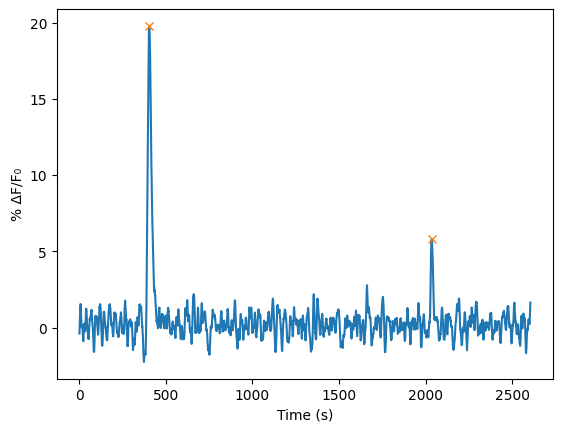

'\n# store number of events, frequency of events, length of events, and prominences of each event in a list \nimport pandas as pd \n\nnum_of_events =[]\nfreq_of_events = []\nlength_of_events = []\nprominences_of_events = []\n\nnum_of_events.append(num_of_peaks)\nfreq_of_events.append(freq_events)\nlength_of_events.append(widths_seconds)\nprominences_of_events.append(prominences)\n\n# store these lists in a dataframe \nfile_path = Path(movie_path)\nfilename = file_path.name\nfilename = filename.removesuffix(".csv")\nfilename = filename + "_extraresults"\nprint(f"CSV file will be called {filename}")\n\nextra_data = pd.DataFrame({\'num_of_events\':num_of_events,\'freq_of_events (events/s)\':freq_of_events, \'length_of_events (s)\':length_of_events, \'prominences_of_events (% ∆F/F)\':prominences_of_events})\nextra_data.to_csv(filename+\'.csv\', index=True)\n'

In [472]:
# find the peak prominences (basically how much ∆F/F the signal changes compared to noise)

from scipy.signal import peak_prominences

prominences, left_bases, right_bases = peak_prominences(dF, peaks) # left and right bases don't matter 

print(f"The prominence of the signals are {prominences}")


plt.plot(time, dF)
plt.plot(time[peaks], dF[peaks], "x", label='Peaks')
plt.xlabel("Time (s)")
plt.ylabel("% ΔF/F₀")
plt.show()
'''
# store number of events, frequency of events, length of events, and prominences of each event in a list 
import pandas as pd 

num_of_events =[]
freq_of_events = []
length_of_events = []
prominences_of_events = []

num_of_events.append(num_of_peaks)
freq_of_events.append(freq_events)
length_of_events.append(widths_seconds)
prominences_of_events.append(prominences)

# store these lists in a dataframe 
file_path = Path(movie_path)
filename = file_path.name
filename = filename.removesuffix(".csv")
filename = filename + "_extraresults"
print(f"CSV file will be called {filename}")

extra_data = pd.DataFrame({'num_of_events':num_of_events,'freq_of_events (events/s)':freq_of_events, 'length_of_events (s)':length_of_events, 'prominences_of_events (% ∆F/F)':prominences_of_events})
extra_data.to_csv(filename+'.csv', index=True)
'''

In [ ]:
# secondary threshold 
if num_of_peaks == 0:
    for i in range(len(thresholded)):
        thresholded[i] = 0

print(thresholded)

AUC is 256.995445775411 and the total activity is 1.4270389570515352 %dF/Fs


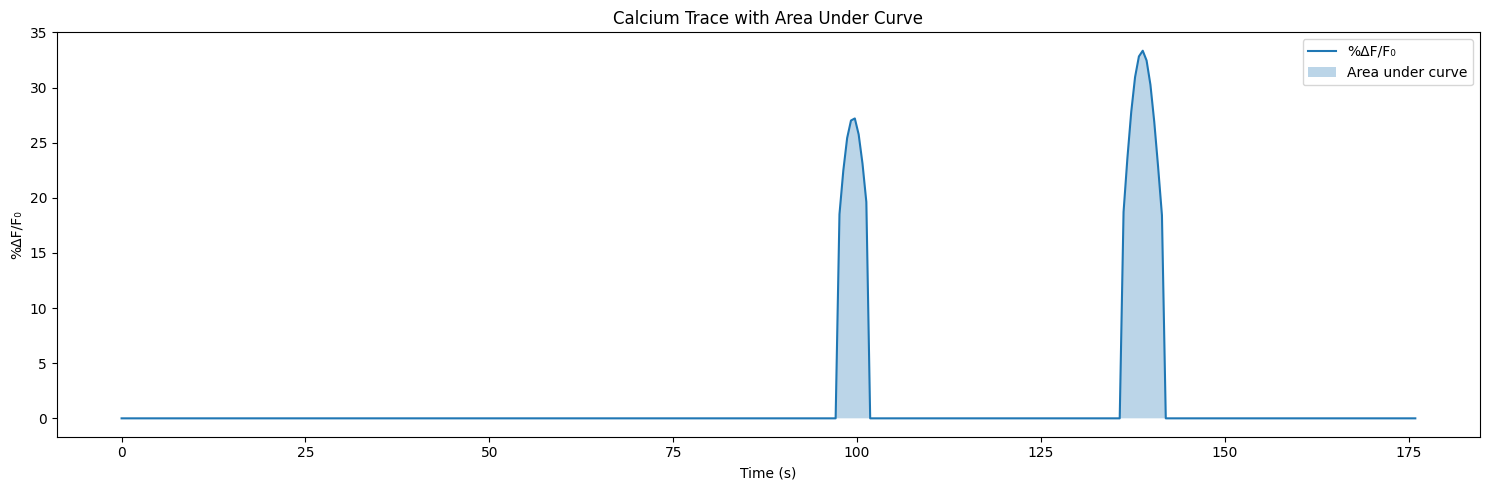

In [421]:
# finding activity via AUC
from scipy.integrate import simpson


t = np.arange(0, endpoint, dt)
auc = simpson(thresholded, t)
activity = auc/time_end
print(f"AUC is {auc} and the total activity is {activity} %dF/Fs")

plt.figure(figsize=(15, 5)) 
plt.plot(t, dF_over_F, label='%ΔF/F₀', )
plt.fill_between(t, dF_over_F, alpha=0.3, label='Area under curve') #alpha used for blending (values from 0-1) 
plt.xlabel('Time (s)')
plt.ylabel('%ΔF/F₀')
plt.title('Calcium Trace with Area Under Curve')
plt.legend()
plt.tight_layout()
plt.show()